# ソフトマージンSVM 完全学習ラボ — 教科書5.3節（98–108ページ）

**対象**：線形分離不可能な場合の線形SVM。ハードマージンとの比較、スラック変数、ヒンジ損失、ラグランジュ双対、KKT条件、サポートベクトル、SMOの2変数更新までを再現します。

**教科書との対応**：式(5.51)–(5.55), (5.61)–(5.62), (5.66), (5.76)–(5.90), (5.97)–(5.106)、図5.5–5.7。

> **重要**：教科書の図5.6・5.7の座標データは写真には掲載されていません。このNotebookは別途生成した400点の線形分離不可能な実験データを使います。教科書にある **C=0.1 と C=10** の比較条件だけを揃えます。教科書のサポートベクトル数（37対15）、マージン幅（1.454対0.693）は本実験の結果とは一致する必要がありません。

**必要なライブラリ**：`numpy`, `matplotlib`, `scipy`, `scikit-learn`（通常のColab環境で利用可能）。上から順に実行してください。

## 1. 何を学習する？（主問題・スラック変数）

識別関数は $g(x)=w^Tx+w_0$、ラベルは $b_k\in\{-1,+1\}$。

**ハードマージン（線形分離可能のみ）**
$$\min_{w,w_0}\frac12\|w\|^2\quad\text{s.t. }b_k g(x_k)\ge1.$$

**ソフトマージン（式5.53–5.55）**
$$\boxed{\min_{w,w_0,\xi}\frac12\|w\|^2+C\sum_k\xi_k\quad\text{s.t. }b_k g(x_k)\ge1-\xi_k,\;\xi_k\ge0.}$$

教科書の $c_{pe}$ を、以下では一般的な記号 $C$ と書きます。**$C$ はスラック違反の重み**。十分大きければ違反を重く評価し、小さいとマージンの広さを重視しやすくなります。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.svm import SVC
from sklearn.datasets import make_moons

np.set_printoptions(precision=5, suppress=True)
print("環境の準備ができました")

環境の準備ができました


## 2. スラック変数＝ヒンジ損失を数値で理解する（式5.61）

2つの制約 $\xi_k\ge 1-b_kg(x_k)$ および $\xi_k\ge0$ を満たす**最小**のスラックは
$$\boxed{\xi_k=\max(0,1-b_k g(x_k))}.$$

$\xi=0$：マージンを満たす。$0<\xi<1$：正しく分類するがマージン違反。$\xi=1$：決定境界。$\xi>1$：誤分類。

注意：この式は「制約のみ」ではなく、$C>0$ の目的関数のもとで最適な $\xi$ に対して成立します。

符号付きスコア     スラックxi       解釈
      1.50           0.00          マージン外側/境界
      1.00           0.00          マージン外側/境界
      0.40           0.60          マージン内(正解)
      0.00           1.00          決定境界
     -0.30           1.30          誤分類


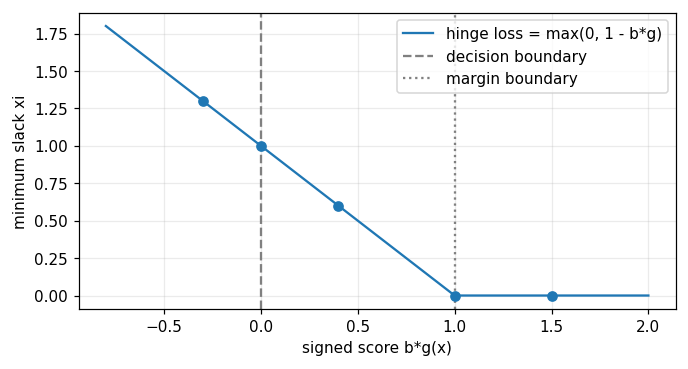

In [2]:
scores = np.array([1.5, 1.0, 0.4, 0.0, -0.3])  # b_k*g(x_k)
xi = np.maximum(0.0, 1.0 - scores)
print("符号付きスコア     スラックxi       解釈")
for s, z in zip(scores, xi):
    category = "マージン外側/境界" if z == 0 else ("マージン内(正解)" if z < 1 else ("決定境界" if z == 1 else "誤分類"))
    print(f"{s:>10.2f}          {z:>5.2f}          {category}")
xx = np.linspace(-0.8, 2, 280)
plt.figure(figsize=(7,3.5))
plt.plot(xx, np.maximum(0,1-xx), label='hinge loss = max(0, 1 - b*g)')
plt.axvline(0, color='gray', ls='--', label='decision boundary')
plt.axvline(1, color='gray', ls=':', label='margin boundary')
plt.scatter(scores, xi, zorder=4)
plt.xlabel('signed score b*g(x)'); plt.ylabel('minimum slack xi'); plt.legend();plt.grid(alpha=.25);plt.show()

## 3. 小さなデータでSVMを**手計算に近い形**で学ぶ

以下の5点には、同じ座標 $x=0$ に異なるラベルがあるため、**ハードマージンは不可能**です。ソフトマージンなら解けます。

入力は1次元なので $g(x)=wx+w_0$ とします。実装では `SVC(kernel="linear")` を使い、最適な双対係数・スラック・サポートベクトルを点検します。

In [3]:
X5 = np.array([[-2.0],[-1.0],[0.0],[0.0],[2.0]])
y5 = np.array([-1,-1,1,-1,1])
C5 = 1.0
small = SVC(kernel='linear', C=C5, tol=1e-10).fit(X5,y5)
w5 = small.coef_.ravel(); b05 = float(small.intercept_[0])
s5 = y5 * small.decision_function(X5)
xi5 = np.maximum(0, 1-s5)
alpha5 = np.zeros(len(y5))
alpha5[small.support_] = np.abs(small.dual_coef_.ravel())
print('w=', w5, 'w0=', b05)
print('k   x     label   b*g      xi      alpha')
for k in range(len(y5)):
    print(f'{k+1:1d} {X5[k,0]:6.1f} {y5[k]:5d} {s5[k]:8.4f} {xi5[k]:8.4f} {alpha5[k]:9.5f}')
print('objective =', 0.5*w5@w5 + C5*xi5.sum())
print('support indices (1-origin) =', small.support_+1)

w= [0.66667] w0= -0.3333333333333333
k   x     label   b*g      xi      alpha
1   -2.0    -1   1.6667   0.0000   0.00000
2   -1.0    -1   1.0000   0.0000   0.22222
3    0.0     1  -0.3333   1.3333   1.00000
4    0.0    -1   0.3333   0.6667   1.00000
5    2.0     1   1.0000   0.0000   0.22222
objective = 2.2222222222222223
support indices (1-origin) = [2 4 3 5]


## 4. なぜラグランジュ関数が式(5.66)になる？

制約を $1-\xi_k-b_kg(x_k)\le0$ および $-\xi_k\le0$ と書くと、非負乗数 $\lambda_k,\gamma_k$ により

$$\begin{aligned}
L&=\frac12\|w\|^2+C\sum_k\xi_k
-\sum_k\lambda_k[b_k(w^Tx_k+w_0)-1+\xi_k]
-\sum_k\gamma_k\xi_k.
\end{aligned}$$

停留条件を計算すると
$$\boxed{w=\sum_k\lambda_k b_kx_k},\qquad \boxed{\sum_k\lambda_k b_k=0},\qquad \boxed{C-\lambda_k-\gamma_k=0}.$$

$\gamma_k\ge0,\lambda_k\ge0$ より **$0\le\lambda_k\le C$**。これがハードマージンとの双対制約の差です。

## 5. 双対問題の導出とグラム行列（式5.83–5.90）

上の停留条件をラグランジュ関数へ代入すると
$$D(\lambda)=\sum_k\lambda_k-\frac12\sum_{i,j}\lambda_i\lambda_jb_ib_j x_i^Tx_j.$$

$G_{ij}=x_i^Tx_j$, $H_{ij}=b_ib_jG_{ij}$ と定義すれば
$$\boxed{\max_\lambda\; \boldsymbol{1}^T\lambda-\frac12\lambda^TH\lambda\quad\text{s.t. }\lambda^Tb=0,\;0\le\lambda\le C.}$$

$H=\operatorname{diag}(b)G\operatorname{diag}(b)$ は半正定値であり、$D$ は凹関数です。$G$ と $H$ は同じ行列ではありません。

In [4]:
G5 = X5 @ X5.T
H5 = (y5[:,None]*y5[None,:]) * G5
print('Gram G =\n',G5)
print('H =\n',H5)
print('H の固有値 =',np.linalg.eigvalsh(H5))
print('alpha の等式制約 =',alpha5 @ y5)
print('alpha の範囲 =',alpha5.min(), alpha5.max())
assert np.linalg.eigvalsh(H5).min() > -1e-8

Gram G =
 [[ 4.  2.  0.  0. -4.]
 [ 2.  1.  0.  0. -2.]
 [ 0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.]
 [-4. -2.  0.  0.  4.]]
H =
 [[ 4.  2. -0.  0.  4.]
 [ 2.  1. -0.  0.  2.]
 [-0. -0.  0. -0.  0.]
 [ 0.  0. -0.  0. -0.]
 [ 4.  2.  0. -0.  4.]]
H の固有値 = [-0. -0.  0.  0.  9.]
alpha の等式制約 = 0.0
alpha の範囲 = 0.0 1.0


## 6. QPを直接解く（SciPy / SLSQP）

SciPyの `minimize` に負の双対目的関数を渡して、$\lambda$ の最適化を実際に行います。`SLSQP` は**汎用の制約付き最適化法**であり、QP専用ソルバーではありません。ここでは教材として使います。

双対の目的関数を最大化する代わりに $-D(\lambda)$ を最小化します。

In [5]:
def solve_dual_qp(X, y, C):
    y = np.asarray(y, dtype=float)
    H = (y[:,None]*y[None,:]) * (X @ X.T)
    n = len(y)
    objective = lambda a: 0.5*a @ H @ a - a.sum()
    gradient = lambda a: H @ a - np.ones(n)
    result = minimize(objective, np.zeros(n), jac=gradient,
                      method='SLSQP', bounds=[(0, C)]*n,
                      constraints=[{'type':'eq','fun':lambda a: a @ y,
                                    'jac':lambda a: y}],
                      options={'ftol':1e-12,'maxiter':3000})
    if not result.success:
        raise RuntimeError(result.message)
    return result.x, H, result

alpha_qp, H_qp, result = solve_dual_qp(X5, y5, C5)
w_qp = ((alpha_qp*y5)[:,None]*X5).sum(axis=0)
print('QP alpha=',alpha_qp)
print('sklearn alpha=',alpha5)
print('QP w=',w_qp,' sklearn w=',w5)
print('max |alpha difference|=',np.max(np.abs(alpha_qp-alpha5)))
print('constraint alpha @ y =',alpha_qp @ y5)
assert np.allclose(w_qp, w5, atol=2e-4)
assert np.isclose(alpha_qp @ y5,0,atol=1e-6)

QP alpha= [0.      0.22222 1.      1.      0.22222]
sklearn alpha= [0.      0.22222 1.      1.      0.22222]
QP w= [0.66667]  sklearn w= [0.66667]
max |alpha difference|= 1.1046719095020308e-14
constraint alpha @ y = -6.661338147750939e-15


## 7. KKT条件を数値で検証（式5.67–5.75）

**KKT条件**：
- 停留：$w=\sum\lambda_kb_kx_k$, $\sum\lambda_kb_k=0$, $C=\lambda_k+\gamma_k$
- 主実行可能：$m_k-1+\xi_k\ge0$, $\xi_k\ge0$（$m_k=b_kg(x_k)$）
- 双対実行可能：$\lambda_k,\gamma_k\ge0$
- 相補性：$\lambda_k(m_k-1+\xi_k)=0$, $\gamma_k\xi_k=0$

$\gamma_k=C-\lambda_k$ としてすべて検証します。

In [6]:
gamma5 = C5-alpha5
residual = s5-1+xi5
print('min margin feasibility  =', residual.min())
print('min gamma              =', gamma5.min())
print('max |lambda*residual|  =', np.max(np.abs(alpha5*residual)))
print('max |gamma*xi|         =', np.max(np.abs(gamma5*xi5)))
print('||w - sum alpha*y*x||  =', np.linalg.norm(w5 - ((alpha5*y5)[:,None]*X5).sum(axis=0)))
print('|sum alpha*y|          =', np.abs(alpha5@y5))
assert residual.min() > -1e-5
assert np.max(np.abs(alpha5*residual)) < 1e-4
assert np.max(np.abs(gamma5*xi5)) < 1e-4

min margin feasibility  = 0.0
min gamma              = 0.0
max |lambda*residual|  = 0.0
max |gamma*xi|         = 0.0
||w - sum alpha*y*x||  = 0.0
|sum alpha*y|          = 0.0


## 8. $\lambda$ と $\xi$ の3つのケース（式5.101–5.106）

$\lambda_k=0$ なら $\xi_k=0$ かつ $m_k\ge1$。

$0<\lambda_k<C$ なら $\xi_k=0$ かつ $m_k=1$。このような点から $w_0=b_s-w^Tx_s$ を求められます。

$\lambda_k=C$ なら $m_k=1-\xi_k$。$\xi_k=0$（境界上）、$0<\xi_k<1$（正解だがマージン内）、$\xi_k=1$（決定境界上）、$\xi_k>1$（誤分類）のいずれも理論上あり得ます。

**教科書の注意点**：境界上の点に $\lambda=0$ または $\lambda=C,\xi=0$ となる退化的ケースもあり得るため、単純な「必ず $>$」の分類には例外があります。

In [7]:
tol = 1e-6
for k,(a,s,z) in enumerate(zip(alpha5,s5,xi5),start=1):
    case = 'lambda=0' if a<tol else ('0<lambda<C' if a<C5-tol else 'lambda=C')
    print(f'point {k}: {case:12s}  signed margin={s:6.3f}, slack={z:6.3f}')
free = np.where((alpha5>tol) & (alpha5<C5-tol))[0]
if len(free):
    candidate_biases = y5[free] - X5[free]@w5
    print('自由サポートベクトルから復元したバイアス：',candidate_biases,
          '平均=',candidate_biases.mean())
else:
    print('0<lambda<C の点なし → この単純公式は使えず、KKT境界の検討が必要')

point 1: lambda=0      signed margin= 1.667, slack= 0.000
point 2: 0<lambda<C    signed margin= 1.000, slack= 0.000
point 3: lambda=C      signed margin=-0.333, slack= 1.333
point 4: lambda=C      signed margin= 0.333, slack= 0.667
point 5: 0<lambda<C    signed margin= 1.000, slack= 0.000
自由サポートベクトルから復元したバイアス： [-0.33333 -0.33333] 平均= -0.3333333333333333


## 9. 教科書図5.6・5.7に対応する $C=0.1$ と $C=10$ の比較

ここから **400点の別データ**を使います。元の図と同様に2クラスが重なり、直線では完全分離できません。両方の $C$ で学習して、決定境界 $g=0$ とマージン境界 $g=\pm1$ を描きます。

色付きの大きな輪がサポートベクトル（$\lambda_k>0$）です。図中の点数・マージン幅は、このNotebook固有の結果です。

データ数= 400 クラスごと= [200 200]


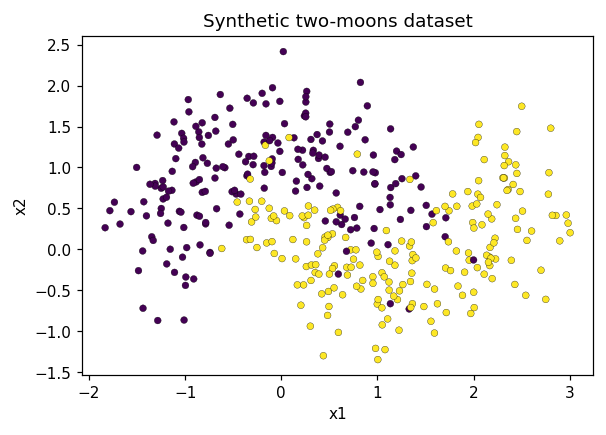

In [8]:
Xraw, yraw = make_moons(n_samples=400, noise=0.28, random_state=21)
# データを傾けて、非線形な分布を保ちつつ視覚的に教科書と類似した構成にする
X = Xraw @ np.array([[1.2, 0.25],[-0.3, 1.4]])
y = 2*yraw-1
print('データ数=',len(y),'クラスごと=',np.bincount(yraw))
plt.figure(figsize=(6,4))
plt.scatter(X[:,0],X[:,1],c=y,s=20,edgecolors='k',linewidths=.2)
plt.xlabel('x1');plt.ylabel('x2');plt.title('Synthetic two-moons dataset');plt.show()

C=  0.10, SV=166, violations=163, errors= 67, margin width=1.3920
C= 10.00, SV=144, violations=141, errors= 66, margin width=1.1606


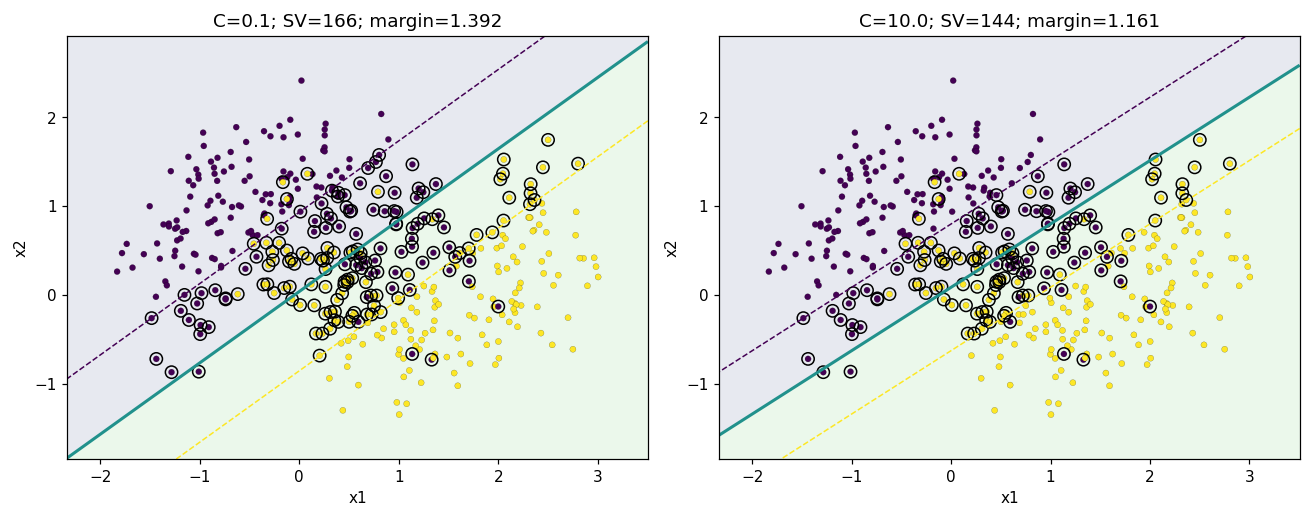

In [9]:
def fit_and_describe(X,y,C):
    model=SVC(kernel='linear', C=C, tol=1e-8, max_iter=500000).fit(X,y)
    w=model.coef_[0]; bias=model.intercept_[0]
    signed=y*model.decision_function(X)
    xi=np.maximum(0,1-signed)
    alpha=np.zeros(len(y));alpha[model.support_]=np.abs(model.dual_coef_[0])
    n_sv=np.count_nonzero(alpha>1e-6)
    n_error=np.count_nonzero(signed<0)
    n_violation=np.count_nonzero(xi>1e-6)
    margin=2/np.linalg.norm(w)
    print(f'C={C:6.2f}, SV={n_sv:3d}, violations={n_violation:3d}, errors={n_error:3d}, margin width={margin:.4f}')
    return model,w,bias,signed,xi,alpha

runs={C:fit_and_describe(X,y,C) for C in [0.1,10.0]}
fig, axs=plt.subplots(1,2,figsize=(12,4.8))
xx, yy=np.meshgrid(np.linspace(X[:,0].min()-.5,X[:,0].max()+.5,250),
                   np.linspace(X[:,1].min()-.5,X[:,1].max()+.5,250))
pts=np.c_[xx.ravel(), yy.ravel()]
for ax,(C,(model,w,bias,signed,xi,alpha)) in zip(axs,runs.items()):
    Z=model.decision_function(pts).reshape(xx.shape)
    ax.contourf(xx,yy,Z>0,alpha=.12)
    ax.contour(xx,yy,Z,levels=[-1,0,1],linestyles=['--','-','--'],linewidths=[1,2,1])
    ax.scatter(X[:,0],X[:,1],c=y,s=16,edgecolors='k',linewidths=.1)
    ax.scatter(model.support_vectors_[:,0],model.support_vectors_[:,1],
               s=65,facecolors='none',edgecolors='black',linewidths=1)
    ax.set_title(f'C={C}; SV={len(model.support_)}; margin={2/np.linalg.norm(w):.3f}')
    ax.set_xlabel('x1');ax.set_ylabel('x2')
plt.tight_layout();plt.show()

### なぜ $C$ によって学習結果が変わるのか？

目的関数 $\frac12\|w\|^2+C\sum\xi_k$ における、**マージンを広げるコスト**と**マージン違反のコスト**の相対的な重みが変わるためです。

$C$ が大きいと**一般に違反を強く抑制する傾向**がありますが、サポートベクトル数やマージン幅がすべてのデータ集合で単調に変化するとは限りません。教科書の数値（37→15、1.454→0.693）は特定のデータでの観測です。

また、**マージン幅** $2/\|w\|$ は2本のスコア境界の距離です。線形分離不可能な場合、その帯の内側にデータが存在しても構いません。

## 10. SMOの核心を2データで手計算する

SMO（逐次最小最適化）は、等式制約 $\sum\lambda_kb_k=0$ を維持するよう**2つの係数**を同時に更新し、それ以外の係数を固定します。

ここでは2つだけの1次元学習データ $x_1=-2,b_1=-1$、$x_2=2,b_2=+1$ を考えます。等式制約から $\lambda_1=\lambda_2=t$。

$H=\begin{pmatrix}4&4\\4&4\end{pmatrix}$ より、双対目的は $D(t)=2t-8t^2$ となり、$t^*=1/8$（$C\ge1/8$ のとき）。$C<1/8$ なら $t^*=C$ です。

この例では一度の「2変数最適化」で最適解を求められます。一般のSMOでは、ペア選択・更新・KKT確認を何度も繰り返します。

H=
 [[4. 4.]
 [4. 4.]]
C=0.05, t*=0.05000, D(t*)=0.08000
C=0.2, t*=0.12500, D(t*)=0.12500
C=1.0, t*=0.12500, D(t*)=0.12500


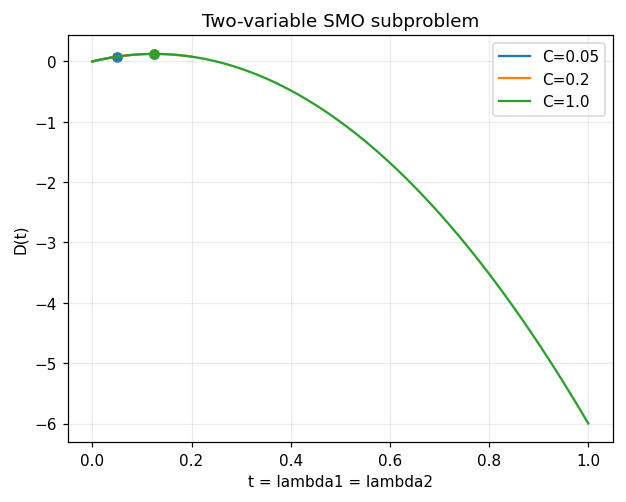

In [10]:
Xp = np.array([[-2.],[2.]])
yp = np.array([-1.,1.])
Hp = (yp[:,None]*yp[None,:])*(Xp@Xp.T)
print('H=\n',Hp)
for C in [0.05,0.2,1.0]:
    tstar=min(C,1/8)
    t=np.linspace(0,C,250)
    D=2*t-8*t*t
    print(f'C={C}, t*={tstar:.5f}, D(t*)={2*tstar-8*tstar**2:.5f}')
    plt.plot(t,D,label=f'C={C}')
    plt.scatter([tstar],[2*tstar-8*tstar**2])
plt.xlabel('t = lambda1 = lambda2');plt.ylabel('D(t)')
plt.title('Two-variable SMO subproblem');plt.legend();plt.grid(alpha=.25);plt.show()

## 11. 発展：スラック変数を含む主問題を解く（双対問題との比較）

スラック変数を消去した主問題は
$$\min_{w,w_0}\frac12\|w\|^2+C\sum_k\max(0,1-b_k(w^Tx_k+w_0)).$$

ここでは小データ5点に対し、主問題の $w,w_0,\xi$ を**明示的に** SLSQP で解き、双対解と最適値が一致すること（強双対性）を確認します。

In [11]:
def solve_primal_qp(X,y,C):
    n,d=X.shape
    # z=[w(0:d),bias(d),xi(d+1:)]
    def obj(z):return 0.5*z[:d]@z[:d]+C*z[d+1:].sum()
    def grad(z):return np.r_[z[:d],0.,np.full(n,C)]
    # signed margin - 1 + xi >= 0
    A=np.zeros((n,d+1+n))
    A[:,:d]=y[:,None]*X
    A[:,d]=y
    A[:,d+1:]=np.eye(n)
    return minimize(obj,np.r_[np.zeros(d+1),np.ones(n)],jac=grad,method='SLSQP',
        bounds=[(None,None)]*(d+1)+[(0,None)]*n,
        constraints=[{'type':'ineq','fun':lambda z:A@z-np.ones(n),'jac':lambda z:A}],
        options={'ftol':1e-12,'maxiter':3000})
pr=solve_primal_qp(X5,y5,C5)
if not pr.success: raise RuntimeError(pr.message)
dual_value=alpha_qp.sum()-.5*alpha_qp@H5@alpha_qp
print('primal solution [w, bias, xi...] =',pr.x)
print('primal value =',pr.fun)
print('dual value   =',dual_value)
print('duality gap =',pr.fun-dual_value)
assert abs(pr.fun-dual_value)<1e-6

primal solution [w, bias, xi...] = [ 0.66667 -0.33333  0.       0.       1.33333  0.66667  0.     ]
primal value = 2.222222222222286
dual value   = 2.2222222222222245
duality gap = 6.128431095930864e-14


## 12. 学習チェック（自分で考えてから回答を読む）

1. $b_kg(x_k)=0.25$ のとき、最適なスラック変数はいくつ？
2. $b_kg(x_k)=-0.4$ のデータは正しく分類されている？ スラック変数はいくつ？
3. $\lambda_k=C$ のとき、必ず誤分類なのか？
4. ハードマージンとソフトマージンの双対目的関数は違う？ 制約条件は？
5. SMOで2つの双対変数を一緒に更新する理由は？
6. $C=0.1$ の方が $C=10$ より未知データへの精度が高いと、学習データの図だけから言える？

<details><summary>解答を見る</summary>

1. $\xi=\max(0,1-0.25)=0.75$。
2. 誤分類、$\xi=1.4$。
3. いいえ。$\xi=0$ でマージン境界上、$0<\xi<1$ で正解、$\xi>1$ で誤分類などがあります。
4. 目的関数は同じ。ソフトマージンでは $\lambda_k\le C$ の上限制約が増えます。
5. 等式制約 $\sum_k\lambda_kb_k=0$ を保ちながら更新するため。
6. 言えません。独立した検証データや交差検証が必要です。

</details>

### 次に行う実験
- `C5` を `0.1`, `0.5`, `10` に変えて5点の $\lambda$・$\xi$ を観察。
- 400点の `C=[0.1,10.0]` を `[0.01,0.1,1,10]` に増やして図を比較。
- `X5` の矛盾した重複点の片方を動かして線形分離可能にした場合の変化を見る。
- 追加課題：同じデータで検証精度を計算し、$C$ の選択を検討。

**まとめ**：ソフトマージンSVMの学習は、$\xi$ を導入した凸QPの主問題、または $0\le\lambda\le C$ を持つ双対QPを数値最適化すること。KKT条件は、得られた解の確認とサポートベクトルの役割の理解に使えます。